# Length of stay: Extra trees

Extremely randomized trees: like a random forest, but split thresholds are drawn at random and no bootstrap samples are used. More randomness means lower variance and sometimes higher bias.

**Task:** predict an animal's length-of-stay bin at intake: `<1 week`, `1-4 weeks`, `1-3 months`, `3+ months`. The bins are ordinal.
**Data:** Austin dogs and cats, intake-time features only (`utils.FEATURES`). Train is intakes before 2022 and val is 2022, grouped by animal (see `eda/austindataprocessing.ipynb`).
**Metrics:** accuracy, macro-F1, per-class precision/recall, and quadratic weighted kappa (QWK; rewards predictions that land close to the true bin).
**This notebook uses default hyperparameters** (no tuning). The only exceptions are settings that don't change the model itself: `random_state=utils.SEED`, `n_jobs=-1`, and an iteration cap where the default fails to converge. Tuning comes later.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))  # repo root -> import utils
import utils

RESULTS_DIR = Path("results")
train, val, test = utils.load_los_splits()   # test is held out; models are compared on val
print(f"train {len(train):,}  val {len(val):,}  (test {len(test):,} untouched)")
train["los_bin"].value_counts(normalize=True).reindex(utils.LOS_BIN_LABELS).round(3)

time_group_split: dropped 1,282 rows (0.8%) belonging to animals first seen in an earlier split
train 126,758  val 10,544  (test 21,835 untouched)


los_bin
<1 week       0.559
1-4 weeks     0.262
1-3 months    0.139
3+ months     0.040
Name: proportion, dtype: float64

In [2]:
from sklearn.ensemble import ExtraTreesClassifier

model = ExtraTreesClassifier(n_jobs=-1, random_state=utils.SEED)
model

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


== Extra trees ==  macro-F1 0.327  accuracy 0.484
              precision    recall  f1-score   support

     <1 week       0.52      0.79      0.63      4554
   1-4 weeks       0.42      0.30      0.35      3420
  1-3 months       0.42      0.22      0.29      2017
   3+ months       0.15      0.02      0.04       553

    accuracy                           0.48     10544
   macro avg       0.38      0.33      0.33     10544
weighted avg       0.45      0.48      0.44     10544

quadratic weighted kappa: 0.234


train accuracy 0.994  |  fit 5.9s  predict 0.1s


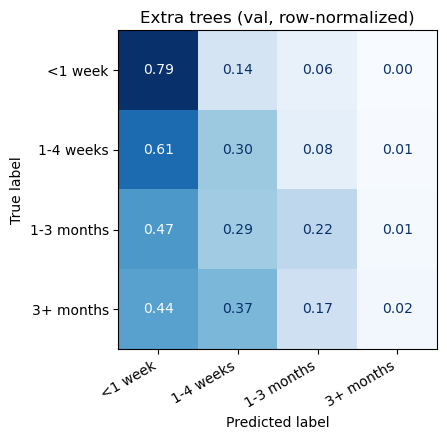

In [3]:
pipe, metrics = utils.evaluate_classifier(model, train, val, name="Extra trees",
                                           results_dir=RESULTS_DIR)

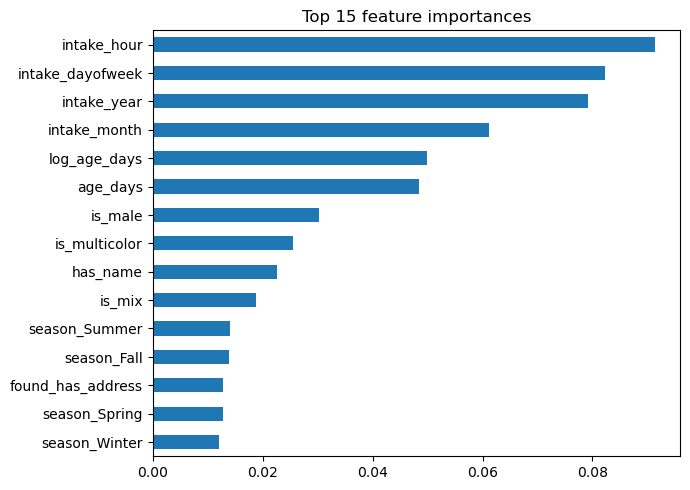

In [4]:
# Impurity-based importances (biased toward high-cardinality / continuous features;
# associations, not causes). Permutation importance is a better check after tuning.
names = pipe.named_steps["pre"].get_feature_names_out()
imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names).nlargest(15)
imp.sort_values().plot(kind="barh", figsize=(7, 5), title="Top 15 feature importances")
plt.tight_layout(); plt.show()

## Hyperparameter tuning (light–medium)

**Randomized search with a time-ordered inner split** (`utils.tune_classifier`):
- Training years are split again, by time and grouped by animal: candidates are fit on intakes before 2021 and scored on 2021 intakes.
- Candidates are ranked by **macro-F1**, so all four bins count equally, not just the dominant `<1 week`.
- The best setting is then refit on the full training set (< 2022) and scored on the **same 2022 val set** as the untuned model.
- Neither val nor test is seen during the search, so the comparison below is fair.

Same search space as the random forest.

In [5]:


base = utils.with_params(model, {})  # unfitted copy of the untuned model
space = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20, 30, None],
    'min_samples_leaf': [1, 2, 5, 10, 20],
    'max_features': ['sqrt', 0.1, 0.2, 0.3],
    'class_weight': [None, 'balanced', 'balanced_subsample'],
}

best, search_results, tune_info = utils.tune_classifier(
    base, space, train, name="Extra trees (tuned)", n_iter=15, results_dir=RESULTS_DIR)
search_results.head(10)

time_group_split: dropped 592 rows (0.5%) belonging to animals first seen in an earlier split


Extra trees (tuned): 15 candidates in 4.4 min | sub-train 115,479, inner-val 10,687 | best inner-val f1_macro 0.374
best params: {'n_estimators': 100, 'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': None, 'class_weight': 'balanced'}


,n_estimators,min_samples_leaf,max_features,max_depth,class_weight,inner_val_f1_macro,mean_fit_time
0,100,2,0.3,None,balanced,0.374133,117.054877
1,300,5,0.3,30,balanced,0.372939,205.606317
2,300,1,0.3,30,balanced_subsample,0.363190,251.012614
3,100,5,0.1,30,balanced_subsample,0.361223,44.926362
4,100,5,0.3,15,balanced_subsample,0.353138,61.902295
5,300,10,sqrt,20,balanced_subsample,0.350742,87.903055
6,100,5,0.3,30,None,0.349813,107.506396
7,300,20,0.3,None,None,0.348242,222.074535
8,300,2,0.3,15,None,0.334325,205.350662
9,200,2,0.1,20,None,0.307752,81.318049


== Extra trees (tuned) ==  macro-F1 0.384  accuracy 0.487
              precision    recall  f1-score   support

     <1 week       0.58      0.65      0.61      4554
   1-4 weeks       0.42      0.41      0.42      3420
  1-3 months       0.40      0.35      0.38      2017
   3+ months       0.16      0.11      0.13       553

    accuracy                           0.49     10544
   macro avg       0.39      0.38      0.38     10544
weighted avg       0.47      0.49      0.48     10544

quadratic weighted kappa: 0.313


train accuracy 0.960  |  fit 12.5s  predict 0.1s


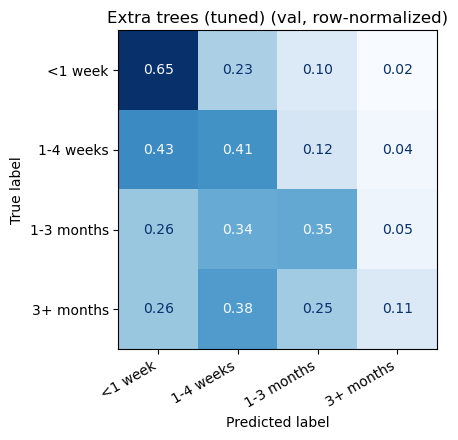

In [6]:
tuned = utils.with_params(base, best)
pipe_tuned, metrics_tuned = utils.evaluate_classifier(
    tuned, train, val, name="Extra trees (tuned)", results_dir=RESULTS_DIR, extra=tune_info)

### Untuned vs. tuned (val 2022)

In [7]:
pd.DataFrame([metrics, metrics_tuned]).set_index("model")[
    ["accuracy", "macro_f1", "qwk", "train_accuracy"]
    + [f"recall_{c}" for c in utils.LOS_BIN_LABELS]].round(3)

,accuracy,macro_f1,qwk,train_accuracy,recall_<1 week,recall_1-4 weeks,recall_1-3 months,recall_3+ months
model,,,,,,,,
Extra trees,0.484,0.327,0.234,0.994,0.793,0.303,0.22,0.024
Extra trees (tuned),0.487,0.384,0.313,0.960,0.650,0.413,0.35,0.107
